# Logistic Regression: Scores, Probabilities, and Decisions

## 1. Introduction and learning objectives

Some targets are categories rather than measurements: a message is unwanted or wanted, a component fails or survives, an event occurs or does not. A useful model can express uncertainty before a final yes/no decision. Logistic regression maps a linear score to a probability and learns by penalizing confident probability errors.

You will connect scores to odds, derive binary cross-entropy from a likelihood, calculate its gradients, implement training without a fitted estimator, and evaluate both probabilities and thresholded decisions. You will also see why convexity does not guarantee finite best-fitting coefficients on perfectly separable data.

Recommended order: [Linear Regression](linear-regression.ipynb), then [Gradient Descent](gradient-descent.ipynb). Independently, you need basic algebra, dot products, and the chain rule; the required probability and logarithm facts are developed here. All labels in this notebook use $0$ and $1$.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 3.01 — Distinguish two prediction questions

**Type:** Conceptual · **Answer:** Markdown

A machine has a measured temperature and vibration level. Explain the difference between predicting its remaining lifetime and predicting whether it fails within a day. For the second task, distinguish a probability estimate from a maintenance decision.

**Expected outcome:** A paragraph identifying target types and why a decision may depend on consequences as well as a predicted probability.

**Your response to Exercise 3.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 2. Prerequisites and mathematical foundations

### Binary outcomes and conditional probabilities

For observation $i$, let $y_i\in\{0,1\}$ be its target and $x_i\in\mathbb R^d$ its features. The set notation means the label has exactly two allowed values. Let $p_i=P(y_i=1\mid x_i)$, where $P$ denotes probability and the vertical bar means "conditional on." A Bernoulli model assigns probabilities $p_i$ and $1-p_i$ to outcomes one and zero.

There are $n$ observations. Matrix $X\in\mathbb R^{n\times d}$ holds row-wise inputs, $w\in\mathbb R^d$ is a weight vector, and scalar $b$ is the intercept. The linear **score**, also called the logit in this model, is

$$
z_i=b+\sum_{j=1}^d X_{ij}w_j,\qquad z=Xw+b\mathbf1_n.
$$

The index $j$ identifies a feature, $\sum$ adds over features, and $\mathbf1_n$ is a length-$n$ vector of ones. A score can be any real number; a probability must lie between zero and one. In NumPy, use `(n,)` arrays for labels, scores, and probabilities, and `(d,)` for weights.

### Exponentials, logarithms, and odds

The exponential $\exp(u)=e^u$, with $e\approx2.71828$, is positive for every real $u$. Its inverse is the natural logarithm $\log$. They satisfy $\log(\exp(u))=u$, $\log(ab)=\log a+\log b$ for positive $a,b$, and derivatives $(d/du)\exp(u)=\exp(u)$ and $(d/du)\log u=1/u$ for $u>0$. These derivatives and the chain rule will convert a product of probabilities into a tractable objective.

For a probability $0<p<1$, its **odds** are $p/(1-p)$. The odds compare the probability of the event to that of its complement. Probability $p=3/4$ has odds three, meaning three times as much probability on the event as on its complement; it is not a probability of three.

Logistic regression assumes a linear relationship for the **log-odds**:

$$
\log\frac p{1-p}=z.
$$

Exponentiating gives $p/(1-p)=e^z$. Multiplying by $1-p$ gives $p=e^z-e^zp$, so $p(1+e^z)=e^z$. Dividing by the positive factor and multiplying numerator and denominator by $e^{-z}$ yields

$$
p=\sigma(z)=\frac1{1+e^{-z}}.
$$

The function $\sigma$ is the sigmoid. It sends zero to $1/2$, large positive scores near one, and large negative scores near zero. A one-unit increase in feature $j$, holding others fixed, adds $w_j$ to the log-odds and multiplies the odds by $e^{w_j}$. It does not add a constant amount to probability.

### Exercise 3.02 — Translate between probability and odds

**Type:** Numerical · **Answer:** Markdown

For probabilities $1/5$, $1/2$, and $4/5$, calculate odds and log-odds. You may leave logarithms in exact symbolic form. Explain which odds correspond to a positive score.

**Expected outcome:** A three-row table with probability, odds, and score, without confusing a ratio with a probability.

**Your response to Exercise 3.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### The sigmoid derivative

Differentiate $\sigma(z)=(1+e^{-z})^{-1}$. The outside inverse gives $-(1+e^{-z})^{-2}$; the inside exponential contributes $-e^{-z}$. Multiplying these derivatives gives

$$
\sigma'(z)=\frac{e^{-z}}{(1+e^{-z})^2}
          =\sigma(z)\bigl[1-\sigma(z)\bigr].
$$

The last equality follows because $1-\sigma(z)=e^{-z}/(1+e^{-z})$. The derivative is positive and at most $1/4$; probabilities are most sensitive to score changes near zero and less sensitive in the tails.

### Exercise 3.03 — Recover the score from a probability

**Type:** Mathematical · **Answer:** Markdown

Starting from $p=\sigma(z)$ with $0<p<1$, rearrange to recover $z=\log[p/(1-p)]$. State why probabilities exactly zero or one have no finite score in this model.

**Expected outcome:** An inverse-function derivation with valid divisions and logarithm domains.

**Your response to Exercise 3.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 3. Theoretical development and worked examples

### A likelihood for observations

For a single Bernoulli outcome, the probability assigned to the observed label can be written $p_i^{y_i}(1-p_i)^{1-y_i}$. If $y_i=1$, the second factor is one; if $y_i=0$, the first factor is one. Assuming the observed outcomes are independent conditional on their inputs and parameters, multiply these terms:

$$
\mathcal L(w,b)=\prod_{i=1}^n p_i^{y_i}(1-p_i)^{1-y_i}.
$$

The symbol $\prod$ means multiply the indexed terms. The likelihood $\mathcal L$ is a function of parameters for the fixed observed data, not a probability distribution over possible parameter vectors. Maximizing it prefers parameters assigning greater probability to what was observed.

Taking a logarithm converts the product into a sum. A logarithm is increasing, so it preserves the maximizing parameters. Negating and averaging converts maximization into minimization:

$$
J(w,b)=\frac1n\sum_i\ell_i,\qquad
\ell_i=-y_i\log p_i-(1-y_i)\log(1-p_i).
$$

This is binary cross-entropy, or average negative log-likelihood. It is not half-MSE. For an observed positive, assigning $p=0.8$ produces loss $-\log0.8\approx0.22314$; assigning $p=0.2$ gives about $1.60944$. Confidently assigning near-zero probability to an observed event is heavily penalized. An individual realized outcome still does not prove that a prior probability estimate was miscalibrated.

### Exercise 3.04 — Score two probability forecasts

**Type:** Numerical · **Answer:** Markdown

For observed labels $(1,0,1)$ and predicted probabilities $(0.6,0.3,0.9)$, write each negative log-likelihood and their mean. Compare the effect of changing only the final probability to $0.01$.

**Expected outcome:** An explicit loss calculation and an explanation of the penalty on a confident error. Approximate logarithms numerically if useful.

**Your response to Exercise 3.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Deriving the gradients

A partial derivative changes one variable while the other inputs and parameters stay fixed; it is written with $\partial$. The notation $\nabla_w J$ collects partial derivatives with respect to all entries of $w$ into a vector. First treat $p$ as the variable for a single example:

$$
\frac{\partial\ell}{\partial p}
=-\frac yp+\frac{1-y}{1-p}
=\frac{p-y}{p(1-p)}.
$$

The common denominator step uses $-y(1-p)+(1-y)p=p-y$. The chain rule then multiplies by $dp/dz=p(1-p)$, giving $\partial\ell/\partial z=p-y$. For finite real logits, $0<p<1$, so this algebra is valid. Numerically, we will avoid explicitly dividing by probabilities near the endpoints.

Since $\partial z_i/\partial w_j=X_{ij}$ and $\partial z_i/\partial b=1$, define residual-like vector $r=p-y$ and obtain

$$
\nabla_w J=\frac1nX^T(p-y),\qquad
\frac{\partial J}{\partial b}=\frac1n\sum_i(p_i-y_i).
$$

The transpose $T$ swaps matrix rows and columns. Shapes are $(d,n)(n)=d$ for weights and scalar for the intercept. These expressions resemble linear regression's gradients, but the predictions now pass through a nonlinear sigmoid and the objective is probabilistic.

**Worked example.** For two one-feature examples $X=(0,1)^T$ and $y=(0,1)^T$, start with $w=b=0$. Both probabilities equal $1/2$. The loss is $\log2\approx0.69315$, the weight gradient is $[0(1/2)+1(-1/2)]/2=-1/4$, and the intercept gradient is zero. A rate of $0.4$ updates the weight to $0.1$ and leaves the intercept unchanged. This is one step, not a completed fit.

### Stable calculations and regularization

Substituting sigmoid into the loss and simplifying gives an equivalent logit expression:

$$
\ell(z,y)=\log(1+e^z)-yz.
$$

To see it, note $\log p=z-\log(1+e^z)$ and $\log(1-p)=-\log(1+e^z)$; substitution combines their coefficients to one. The first term is often called softplus. Directly computing $e^{1000}$ overflows. NumPy's `logaddexp(0, z)` computes $\log(e^0+e^z)$ stably. Use it for the loss rather than first rounding a sigmoid to zero or one and taking logarithms.

For stable probabilities, the equivalent expression $e^z/(1+e^z)$ is safe when $z<0$; the original $1/(1+e^{-z})$ is safe when $z\geq0$. Evaluate branches only on their relevant entries: an eager expression that calculates both exponential branches can still overflow. Do not clip probabilities for the loss while claiming that the unchanged gradient is the exact derivative of that clipped objective.

An optional penalty discourages large weights:

$$
J_\lambda=J+\frac{\lambda}{2}\lVert w\rVert_2^2,\qquad
\nabla_w J_\lambda=\nabla_wJ+\lambda w.
$$

Here $\lambda\geq0$ is a penalty strength, and $\lVert w\rVert_2^2=\sum_jw_j^2$. We exclude the intercept from this penalty, so its gradient is unchanged. This convention puts no extra $1/n$ on the penalty; other texts may define the strength differently. Regularization trades fit to observed data against coefficient magnitude; it should be selected using validation data.

### Exercise 3.05 — Differentiate a penalized objective

**Type:** Mathematical · **Answer:** Markdown

For two features, expand $\frac{\lambda}{2}(w_1^2+w_2^2)$ and derive its contribution to both weight gradients and the intercept gradient. Explain why averaging it again over observations would change the chosen objective.

**Expected outcome:** A derivation tied to the precise normalization above.

**Your response to Exercise 3.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Convexity and the missing finite optimum

With $\widetilde X=[\mathbf1_n\;X]$, the Hessian, or matrix of second derivatives in $\theta=(b,w^T)^T$, is

$$
H=\frac1n\widetilde X^TD\widetilde X,\qquad
D=\operatorname{diag}\bigl(p_i(1-p_i)\bigr).
$$

The operator $\operatorname{diag}$ places its listed entries on a diagonal and zeros elsewhere. For any vector $v$, $v^THv=\frac1n\sum_i p_i(1-p_i)(\widetilde Xv)_i^2\geq0$. Thus logistic-regression loss is convex in its linear parameters.

Nevertheless, if a direction strictly separates every positive and negative example, scaling it can drive the loss toward zero while coefficient magnitudes grow without bound. No finite vector reaches that zero loss. This is different from merely having several finite minimizing vectors. Weight regularization controls weight growth, but an unpenalized intercept can still diverge when the dataset contains only one class. Check data and assumptions rather than interpreting endlessly growing coefficients as ever-better scientific evidence.

### Exercise 3.06 — Interpret a separable dataset

**Type:** Critical · **Answer:** Markdown

On perfectly separable training data, accuracy reaches 100% while unregularized coefficients keep increasing and loss keeps decreasing. Explain why this need not mean an implementation bug. Name two practical checks or modeling changes you would consider.

**Expected outcome:** A distinction between classification accuracy, likelihood optimization, finite optima, and generalization.

**Your response to Exercise 3.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 4. Guided exercises

### Exercise 3.07 — Differentiate a tiny dataset

**Type:** Numerical · **Answer:** Markdown

Let $X=\begin{bmatrix}1&0\\0&1\end{bmatrix}$, $y=(1,0)^T$, $w=(0,0)^T$, and $b=0$. Calculate logits, probabilities, cross-entropy, both weight gradients, and the intercept gradient. Then describe one batch update with a positive learning rate of your choice.

**Expected outcome:** A manual calculation that preserves the observation average and uses one shared pre-update parameter state.

**Your response to Exercise 3.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### A probability is not a decision threshold

Choose a threshold $\tau\in[0,1]$ and define a class prediction $\hat y_i=\mathbb1[p_i\geq\tau]$, where $\mathbb1$ is the indicator: one when the condition holds and zero otherwise. At $\tau=1/2$, this is equivalent to $z_i\geq0$. In two input dimensions, $w_1x_1+w_2x_2+b=0$ is a line; the nonlinear probability transformation has not made the decision boundary nonlinear in the original features.

If a false positive costs $C_{\mathrm{FP}}>0$ and a false negative costs $C_{\mathrm{FN}}>0$, the expected cost of predicting one is $C_{\mathrm{FP}}(1-p)$, while predicting zero costs $C_{\mathrm{FN}}p$. Comparing them gives threshold $C_{\mathrm{FP}}/(C_{\mathrm{FP}}+C_{\mathrm{FN}})$. This calculation assumes probabilities reflect the relevant population and those costs describe the decision. Miscalibration, changing prevalence, or constrained resources require more care.

Define true positives TP as predicted-one/actual-one counts, false positives FP as predicted-one/actual-zero, true negatives TN as predicted-zero/actual-zero, and false negatives FN as predicted-zero/actual-one. Then accuracy is $(TP+TN)/n$, precision is $TP/(TP+FP)$, and recall is $TP/(TP+FN)$. Precision and recall need an explicit policy when their denominators are zero. Accuracy can hide poor positive-class detection when positives are rare.

### Exercise 3.08 — Read a confusion table

**Type:** Numerical · **Answer:** Markdown

A classifier produces TP = 12, FP = 8, TN = 70, and FN = 10. Compute accuracy, precision, and recall. Describe one limitation of reporting only accuracy for these observations.

**Expected outcome:** Three labeled metrics with denominators shown, plus a positive-class interpretation.

**Your response to Exercise 3.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 5. Implementation challenges

An independent derivative check uses a **central difference**. For a scalar parameter coordinate $w_j$ and a small positive perturbation $\epsilon$, compare its analytical derivative to $[J(w+\epsilon e_j,b)-J(w-\epsilon e_j,b)]/(2\epsilon)$, where $e_j$ has a one in coordinate $j$ and zeros elsewhere. Evaluate both losses on the same data and parameter snapshot apart from that one perturbation. Try more than one perturbation size because extremely small differences can suffer floating-point cancellation.

### Exercise 3.09 — Implement stable loss and gradients

**Type:** Programming · **Answer:** Code

Write `logistic_loss_and_gradient(X, y, w, b, penalty=0.0)`. Use the logit loss above, a numerically safe probability calculation, and the stated unpenalized-intercept convention. Require binary labels and compatible one-dimensional targets.

**Expected outcome:** A scalar loss, a weight vector gradient, and a scalar intercept gradient. Include checks on very large positive/negative logits and on the tiny manual dataset without using a high-level estimator.

**Hint:** Keep stable logit evaluation separate from probability evaluation, and check the penalty contribution independently.

In [ ]:
# Your code for Exercise 3.09.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 3.10 — Train a logistic model

**Type:** Programming · **Answer:** Code

Implement a standalone batch or mini-batch training routine using your previous function. Accept a seed when sampling, record full training loss, retain a fixed work budget, and return parameters without selecting a classification threshold inside the fitting loop.

**Expected outcome:** Reproducible training with clearly separated optimization, probability prediction, and class-decision steps.

In [ ]:
# Your code for Exercise 3.10.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 3.11 — Measure probabilities and decisions

**Type:** Programming · **Answer:** Code

Implement probability prediction and threshold-based class prediction. Then implement confusion counts, accuracy, precision, and recall with a documented zero-denominator policy. Verify counts on a manually constructed example.

**Expected outcome:** Explicitly shaped outputs and checks showing that changing the threshold changes decisions without refitting the model.

In [ ]:
# Your code for Exercise 3.11.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 3.12 — Audit a numerical edge case

**Type:** Programming · **Answer:** Code

Construct extreme logits and labels that include confidently wrong predictions. Check finite logit-based losses and bounded probabilities. Compare finite-difference weight gradients to your analytical gradients on a small moderate-logit example, perturbing one parameter at a time.

**Expected outcome:** Numerical evidence for stable evaluation and derivative correctness. Use a small central difference and report the perturbation size; do not treat rounded probability endpoints as exact symbolic zeros.

In [ ]:
# Your code for Exercise 3.12.
# TODO: implement the task above and record the requested checks or plots.

## 6. Experiments and visualizations

This demonstration visualizes only the link function and two individual loss curves. It does not implement a trained classifier. The loss curves score a supplied probability, so they intentionally avoid the endpoints where the logarithm diverges.

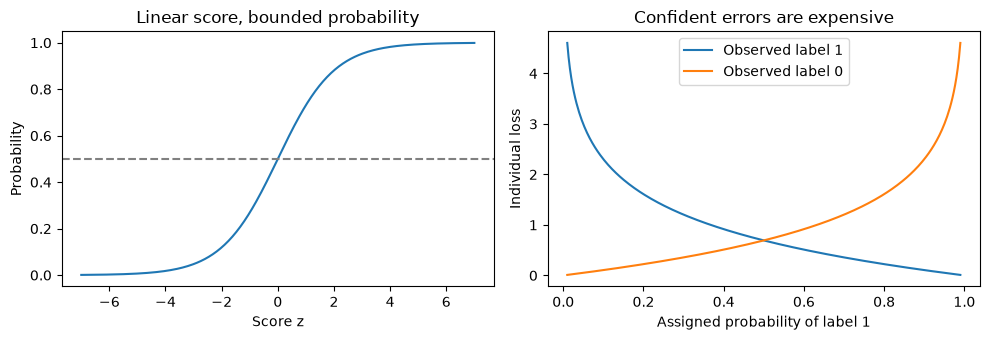

In [6]:
import numpy as np
import matplotlib.pyplot as plt

demo_z = np.linspace(-7, 7, 300)
demo_p = np.linspace(0.01, 0.99, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(demo_z, 1.0 / (1.0 + np.exp(-demo_z)))
axes[0].axhline(0.5, color="gray", linestyle="--")
axes[0].set(xlabel="Score z", ylabel="Probability", title="Linear score, bounded probability")
axes[1].plot(demo_p, -np.log(demo_p), label="Observed label 1")
axes[1].plot(demo_p, -np.log1p(-demo_p), label="Observed label 0")
axes[1].set(xlabel="Assigned probability of label 1", ylabel="Individual loss", title="Confident errors are expensive")
axes[1].legend()
fig.tight_layout()
plt.show()

For the experiment, split observations into training, validation, and test sets. Fit parameters on training data, choose penalty strength, learning rate, and threshold using validation data, then report the final configuration on the untouched test set. If standardizing features, store means and scales from training data and reuse them; a feature with zero scale needs an explicit policy.

The next cell samples labels from a known probability mechanism solely to create data. Because probabilities are not deterministic labels, the classes overlap. There is no trained prediction function here. The test portion must stay out of repeated threshold or parameter selection.

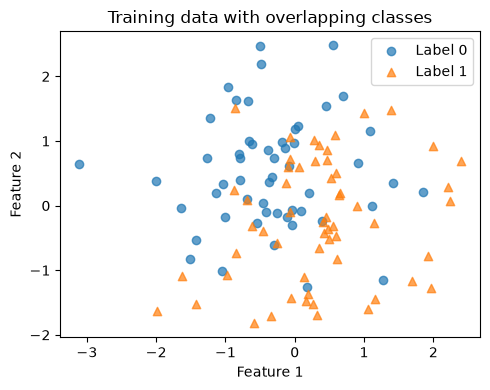

Split sizes: 110 35 35


In [7]:
demo_rng = np.random.default_rng(303)
demo_X = demo_rng.normal(size=(180, 2))
demo_true_scores = 0.2 + 1.4 * demo_X[:, 0] - 0.9 * demo_X[:, 1]
demo_true_p = 1.0 / (1.0 + np.exp(-demo_true_scores))
demo_y = (demo_rng.random(180) < demo_true_p).astype(int)
demo_order = demo_rng.permutation(180)
demo_train_ids = demo_order[:110]
demo_validation_ids = demo_order[110:145]
demo_test_ids = demo_order[145:]
fig, ax = plt.subplots(figsize=(5, 4))
for demo_label, demo_marker in [(0, "o"), (1, "^")]:
    demo_selected = demo_train_ids[demo_y[demo_train_ids] == demo_label]
    ax.scatter(demo_X[demo_selected, 0], demo_X[demo_selected, 1], marker=demo_marker, alpha=0.7, label=f"Label {demo_label}")
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="Training data with overlapping classes")
ax.legend()
fig.tight_layout()
plt.show()
print("Split sizes:", len(demo_train_ids), len(demo_validation_ids), len(demo_test_ids))

### Exercise 3.13 — Fit and inspect probabilities

**Type:** Experimental · **Answer:** Code

Train on the supplied training split. Compare at least two learning rates and two weight penalties using validation cross-entropy. Plot full training loss, validation probabilities against scores, and the two-dimensional decision boundary for a selected configuration.

**Expected outcome:** Labeled plots, recorded work budgets, a declared selection criterion, and no use of test data for tuning. Optimization failure and poor generalization should be reported separately.

In [ ]:
# Your code for Exercise 3.13.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 3.14 — Investigate threshold trade-offs

**Type:** Experimental · **Answer:** Code

Freeze a fitted model. On validation data, vary the threshold and record confusion counts, precision, recall, and a cost using explicitly chosen false-positive/false-negative costs. Select a threshold, then evaluate it once on the test split.

**Expected outcome:** A trade-off visualization and a clearly justified threshold; probability estimates must stay unchanged throughout threshold selection.

In [ ]:
# Your code for Exercise 3.14.
# TODO: implement the task above and record the requested checks or plots.

## 7. Interpretation and critical analysis

A high classification accuracy does not establish calibrated probabilities. Calibration asks whether outcomes occur about as often as the predicted probabilities suggest across comparable cases; finite samples make this uncertain. Cross-entropy rewards assigning probability to observed outcomes, while accuracy discards probability magnitude after thresholding. Their rankings can differ.

The model assumes log-odds are linear in the selected features. Feature interactions or curved boundaries may require a richer representation. Correlation does not establish causal risk, and a representative sample matters: a model trained on one population may be miscalibrated after the event rate changes.

### Exercise 3.15 — Separate uncertainty from correctness

**Type:** Critical · **Answer:** Markdown

Two models predict the same labels at threshold $1/2$ but use different probability magnitudes. Explain how their accuracy can be equal while their cross-entropies differ. Describe what extra evidence would be needed to claim that one is better calibrated.

**Expected outcome:** A distinction between threshold decisions, probabilistic scoring, and empirical calibration.

**Your response to Exercise 3.15**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Exercise 3.16 — Evaluate a costly decision rule

**Type:** Critical · **Answer:** Markdown

A rare positive event is expensive to miss. Explain why choosing the threshold with highest training accuracy may be inappropriate. Identify the data, assumptions, and cost information needed for a defensible alternative.

**Expected outcome:** A validation-based decision argument that does not assume all errors have equal consequences.

**Your response to Exercise 3.16**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 8. Review questions and knowledge checks

### Exercise 3.17 — Connect regression and classification

**Type:** Conceptual · **Answer:** Markdown

Explain how linear and logistic regression share a score structure while differing in output interpretation and loss. Why does applying a sigmoid preserve a linear $1/2$-probability boundary? Why should a logistic weight not be interpreted as a constant probability change?

**Expected outcome:** A coherent explanation connecting score, link, loss, and decision.

**Your response to Exercise 3.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Exercise 3.18 — Verify the curvature claim

**Type:** Mathematical · **Answer:** Markdown

For $H=\widetilde X^TD\widetilde X/n$ and nonnegative diagonal entries of $D$, expand $v^THv$ as a weighted sum of squares. Explain why this proves nonnegative curvature but does not by itself prove a finite, unique minimizer exists.

**Expected outcome:** A dimensionally valid argument and a careful separation of convexity, existence, and uniqueness.

**Your response to Exercise 3.18**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 9. Summary and next learning steps

Logistic regression learns probabilities by mapping a linear score through the sigmoid and minimizing average negative log-likelihood. The gradient's simple form follows from a chain-rule cancellation, while reliable code needs stable logit-based evaluation. Learning a probability model and choosing a decision threshold are distinct tasks, each needing appropriate validation.

Check your extreme-logit calculations, binary label convention, penalty normalization, and threshold protocol before continuing. Next: [Perceptron](../02-neural-networks/perceptron.ipynb), which uses a hard decision and a mistake-driven update instead of a probabilistic likelihood. That contrast will make the need for differentiable multilayer models more concrete.